Health & Biomedical Image Processing Pipeline:
Exploring classical computer vision techniques applied to real clinical data:
1. **Radiology**: Contrast enhancement of Chest X-Rays via CLAHE.
2. **Hematology**: Sickle Cell Anemia detection via morphological circularity.
3. **Dermatology**: Melanoma skin lesion border irregularity (ABCDE rule).
4. **Ophthalmology**: Retinal fundus blood vessel extraction.
5. **Microscopy**: Peripheral blood smear cell segmentation & counting.


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ensure working directory is the repo root
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from toolkit import (
    load_image, to_grayscale, to_rgb,
    blur, apply_clahe, threshold_otsu, morphological_clean,
    canny_edges, find_contours, draw_contours,
    separate_touching_cells, classify_cell, measure_lesion_irregularity, annotate_cells
)
print("Toolkit modules successfully loaded!")


Toolkit modules successfully loaded!


## 1. Radiology: Chest X-Ray Contrast Enhancement (CLAHE)
Standard grayscale normalization vs. Contrast Limited Adaptive Histogram Equalization (CLAHE).
Notice how CLAHE reveals rib contours and spinal vertebrae without saturating lung air cavities.


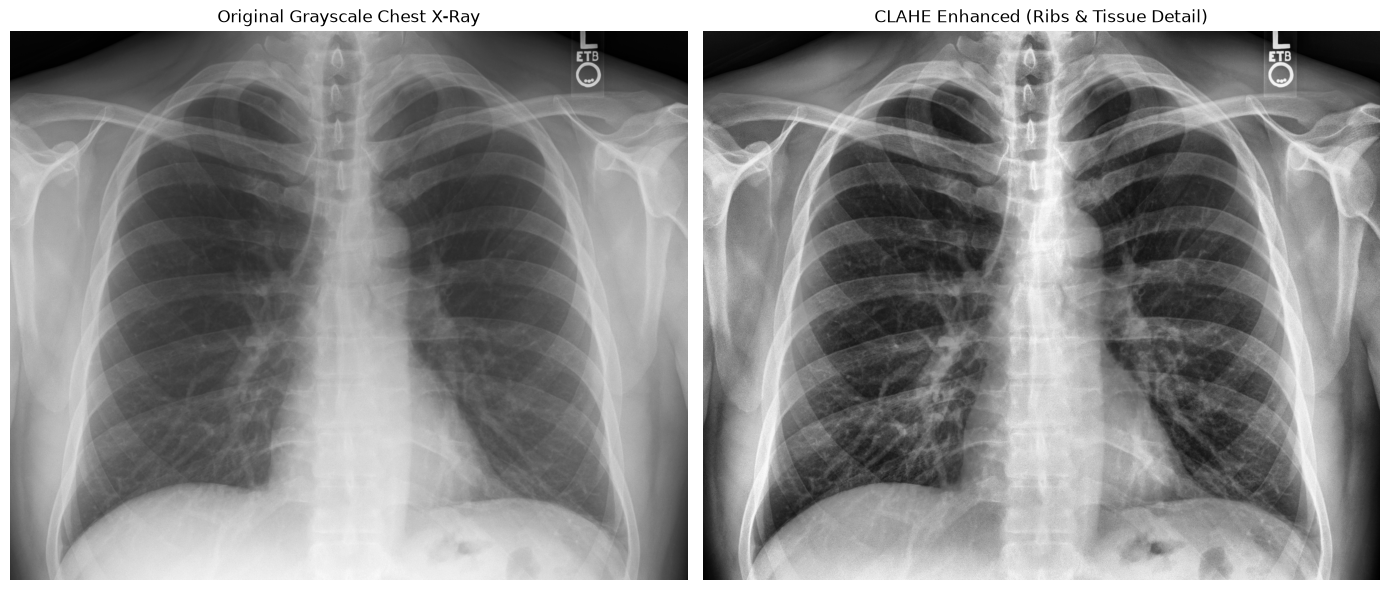

In [2]:
# Load Chest X-Ray
xray = load_image("data/health/chest_xray.png")
xray_gray = to_grayscale(xray)
xray_clahe = apply_clahe(xray_gray, clip_limit=2.5, tile_grid_size=8)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(xray_gray, cmap="gray")
axes[0].set_title("Original Grayscale Chest X-Ray")
axes[0].axis("off")

axes[1].imshow(xray_clahe, cmap="gray")
axes[1].set_title("CLAHE Enhanced (Ribs & Tissue Detail)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


## 2. Hematology: Sickle Cell Anemia Detection
Detecting elongated crescent-shaped sickle cells versus circular healthy red blood cells (RBCs)
using contour circularity and aspect ratio.
- **Green**: Normal circular RBC
- **Red**: Abnormal sickle cell
- **Yellow**: Intermediate / irregular


Total cells detected: 10
  sickle_cell: 8
  normal_rbc: 2


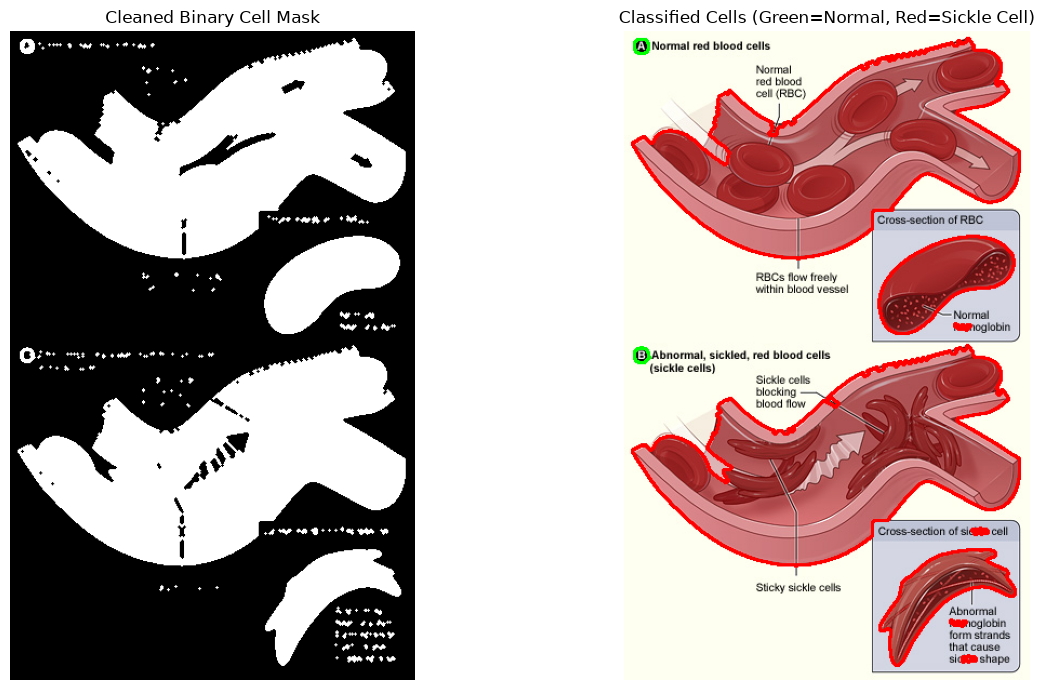

In [3]:
sickle_img = load_image("data/health/sickle_cell.jpg")
sickle_rgb = to_rgb(sickle_img)
sickle_gray = to_grayscale(sickle_img)

# Invert Otsu so dark cells become white foreground (255)
sickle_bin = threshold_otsu(sickle_gray, invert=True)
sickle_clean = morphological_clean(sickle_bin, kernel_size=3)

# Extract cell contours
contours = find_contours(sickle_clean, min_area=35)
cell_types = [classify_cell(c) for c in contours]

annotated = annotate_cells(sickle_rgb, contours, cell_types)

print(f"Total cells detected: {len(contours)}")
for ctype in set(cell_types):
    print(f"  {ctype}: {cell_types.count(ctype)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(sickle_clean, cmap="gray")
axes[0].set_title("Cleaned Binary Cell Mask")
axes[0].axis("off")

axes[1].imshow(annotated)
axes[1].set_title("Classified Cells (Green=Normal, Red=Sickle Cell)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


## 3. Dermatology: Melanoma Border Irregularity (Solidity Metric)
In clinical dermatology, malignant melanomas exhibit scalloped, jagged, irregular borders (the 'B' in ABCDE).
We measure **Solidity** (Contour Area / Convex Hull Area). A low solidity (< 0.88) flags an irregular border.


Lesion Morphometry Analysis: {'area_pixels': 1863874.0, 'perimeter_pixels': 13134.32844030857, 'solidity': 0.855, 'circularity': 0.136, 'is_border_irregular': True}


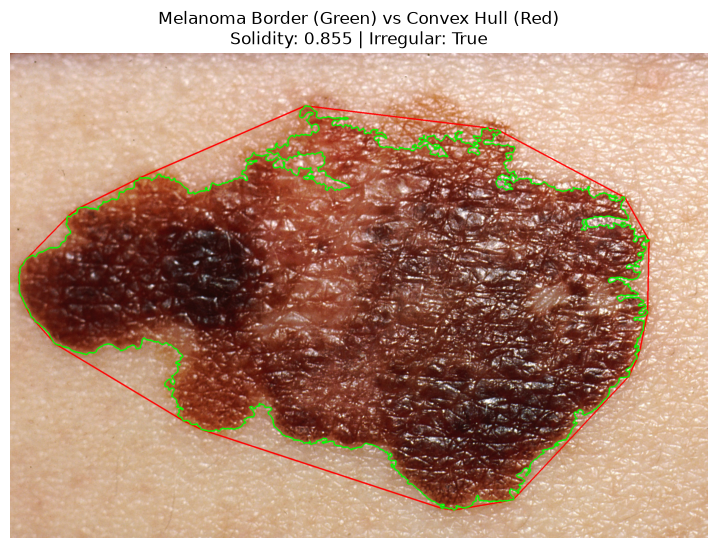

In [4]:
mel_img = load_image("data/health/skin_lesion_melanoma.jpg")
mel_rgb = to_rgb(mel_img)
mel_gray = to_grayscale(mel_img)

# Blur and binarize dark lesion from surrounding skin
mel_blur = blur(mel_gray, kernel_size=15)
mel_bin = threshold_otsu(mel_blur, invert=True)

# Find lesion contour
lesion_contours = find_contours(mel_bin, min_area=1000)
main_lesion = lesion_contours[0]

# Measure clinical metrics
metrics = measure_lesion_irregularity(main_lesion)
print(f"Lesion Morphometry Analysis: {metrics}")

# Draw contour (green) and convex hull (red)
canvas = mel_rgb.copy()
hull = cv2.convexHull(main_lesion)
cv2.drawContours(canvas, [hull], -1, (255, 0, 0), 3)       # Red = Convex Hull
cv2.drawContours(canvas, [main_lesion], -1, (0, 255, 0), 3) # Green = Actual Border

plt.figure(figsize=(9, 7))
plt.imshow(canvas)
plt.title(f"Melanoma Border (Green) vs Convex Hull (Red)\nSolidity: {metrics['solidity']} | Irregular: {metrics['is_border_irregular']}")
plt.axis("off")
plt.show()


## 4. Ophthalmology: Retinal Blood Vessel Segmentation
In fundus imaging, hemoglobin absorbs green light strongly. Therefore, the **Green Channel**
provides the highest contrast for microvascular structures.


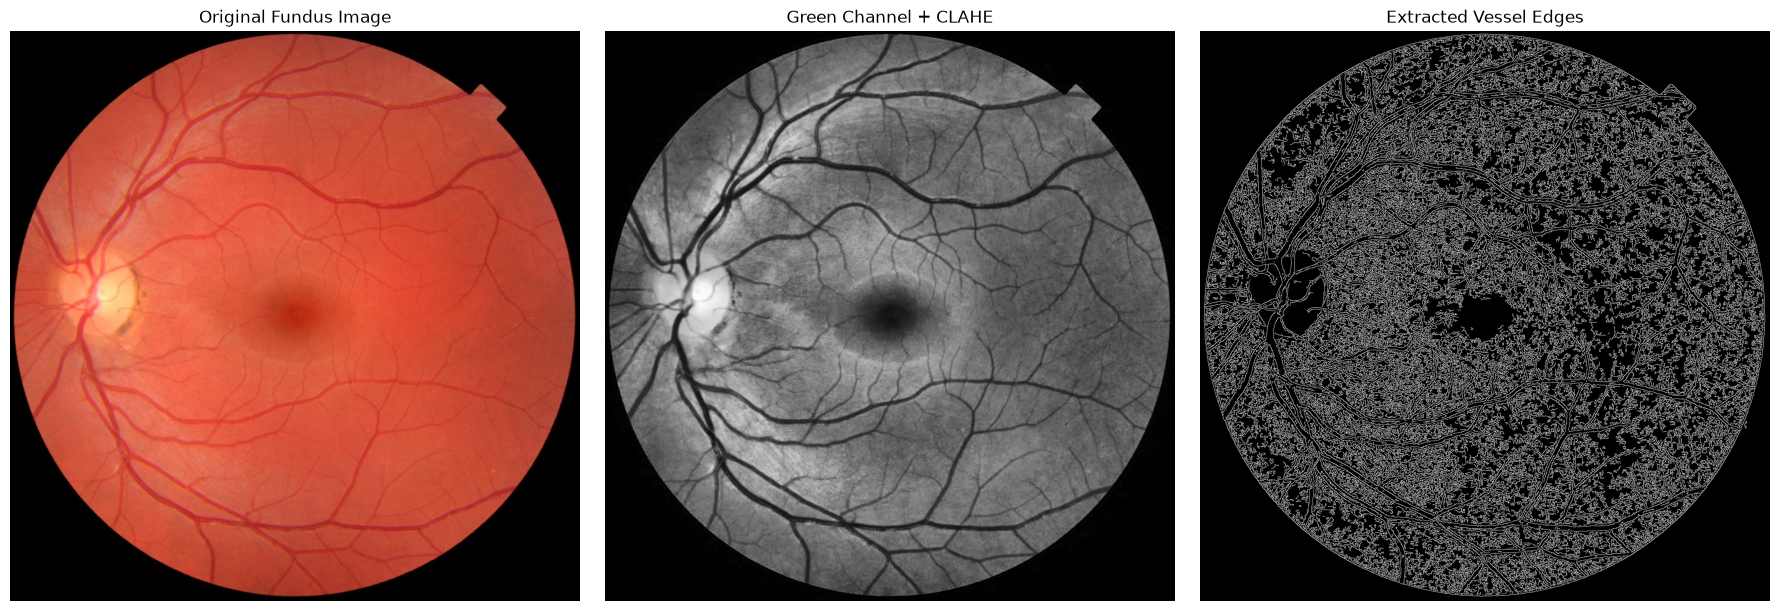

In [5]:
fundus = load_image("data/health/retina_fundus.jpg")
fundus_rgb = to_rgb(fundus)

# Extract Green channel (index 1 in RGB)
green_channel = fundus_rgb[:, :, 1]

# Apply CLAHE to enhance faint microvessels
enhanced_vessels = apply_clahe(green_channel, clip_limit=3.0, tile_grid_size=8)
edges = canny_edges(enhanced_vessels, low=25, high=60)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(fundus_rgb); axes[0].set_title("Original Fundus Image"); axes[0].axis("off")
axes[1].imshow(enhanced_vessels, cmap="gray"); axes[1].set_title("Green Channel + CLAHE"); axes[1].axis("off")
axes[2].imshow(edges, cmap="gray"); axes[2].set_title("Extracted Vessel Edges"); axes[2].axis("off")

plt.tight_layout()
plt.show()


## 5. Microscopy: Blood Smear & Watershed Cell Separation
Under the microscope, red blood cells often clump together.
Using **Distance Transform + Watershed**, we separate touching cell clusters.


Objects detected before watershed: 1
Objects detected after watershed:  1


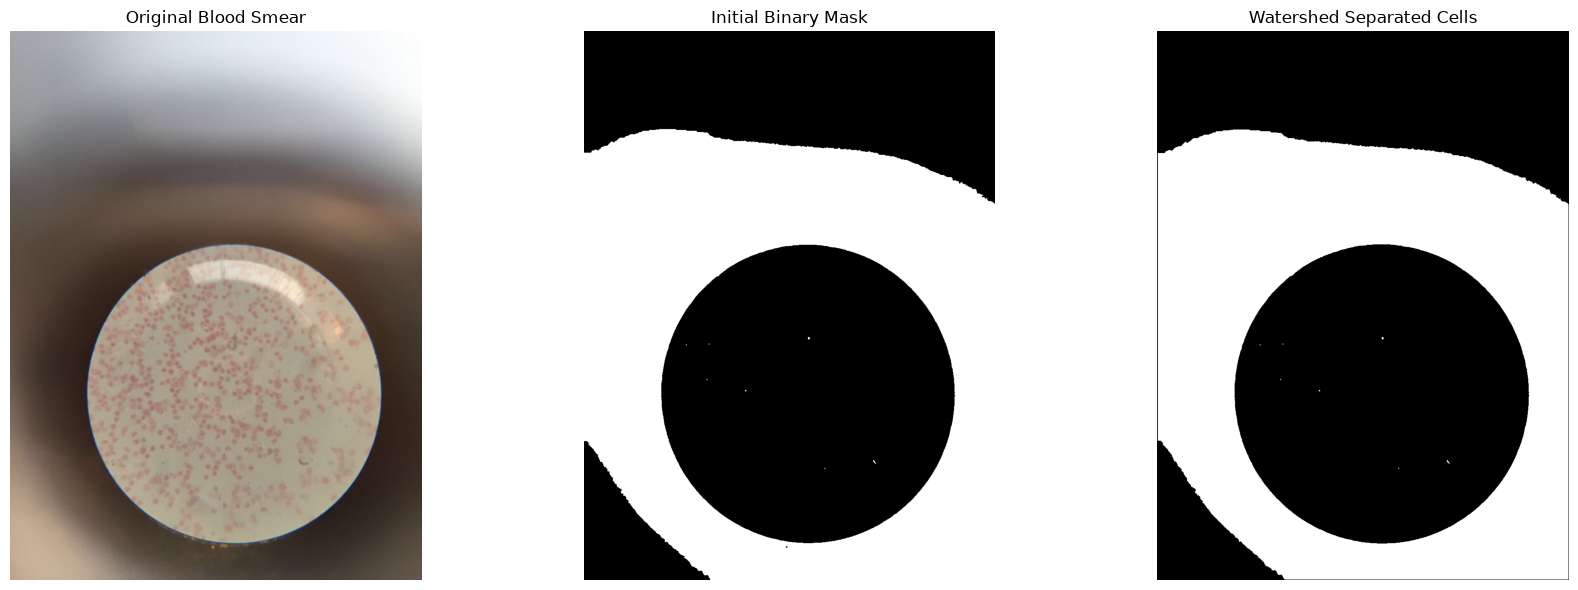

In [6]:
smear = load_image("data/health/blood_smear.jpg")
smear_rgb = to_rgb(smear)
smear_gray = to_grayscale(smear)

# Binarize
smear_bin = threshold_otsu(smear_gray, invert=True)
smear_clean = morphological_clean(smear_bin, kernel_size=3)

# Watershed separation
smear_separated = separate_touching_cells(smear_clean, min_distance_factor=0.3)

cnts_raw = find_contours(smear_clean, min_area=40)
cnts_sep = find_contours(smear_separated, min_area=40)
print(f"Objects detected before watershed: {len(cnts_raw)}")
print(f"Objects detected after watershed:  {len(cnts_sep)}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(smear_rgb); axes[0].set_title("Original Blood Smear"); axes[0].axis("off")
axes[1].imshow(smear_clean, cmap="gray"); axes[1].set_title("Initial Binary Mask"); axes[1].axis("off")
axes[2].imshow(smear_separated, cmap="gray"); axes[2].set_title("Watershed Separated Cells"); axes[2].axis("off")

plt.tight_layout()
plt.show()
